In [1]:
import numpy as np
import time
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, Subset
from torchvision import transforms, datasets
import copy

# What do we do for implementing 2D CNN on our Dataset?

* Connecting to our Drive
* Loading our dataset
* Creating batch sets
* Definig device
* Designing our CNN model
* Train and validation loop
* Saving and Loading our model
* predicting on unseen data

> Note: This library `google.colab` is specific to Google Colab and cannot be used directly in local environments such as VS Code.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Data Preprocessing and Transformations

In [3]:
mean, std = (0.5, 0.5, 0.5), (0.5, 0.5, 0.5)

train_transform = transforms.Compose([transforms.RandomCrop(32, padding= 4),
                                      transforms.RandomHorizontalFlip(),
                                      transforms.ToTensor(),
                                      transforms.Normalize(mean= mean, std= std)])


test_transform = transforms.Compose([transforms.ToTensor(),
                                    transforms.Normalize(mean= mean, std= std)])

## Loading CIFAR-100 Dataset

In [4]:
DATA_DIR= '/content/drive/MyDrive/CIFAR100_Dataset'

traindata = datasets.CIFAR100(root= DATA_DIR,
                              train= True,
                              download= False,
                              transform= train_transform)

validationdata = datasets.CIFAR100(root= DATA_DIR,
                              train= True,
                              download= False,
                              transform= test_transform)

testdata = datasets.CIFAR100(root= DATA_DIR,
                              train= False,
                              download= False,
                              transform= test_transform)

In [5]:
traindata

Dataset CIFAR100
    Number of datapoints: 50000
    Root location: /content/drive/MyDrive/CIFAR100_Dataset
    Split: Train
    StandardTransform
Transform: Compose(
               RandomCrop(size=(32, 32), padding=4)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
               Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
           )

In [6]:
validationdata

Dataset CIFAR100
    Number of datapoints: 50000
    Root location: /content/drive/MyDrive/CIFAR100_Dataset
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
           )

In [7]:
testdata

Dataset CIFAR100
    Number of datapoints: 10000
    Root location: /content/drive/MyDrive/CIFAR100_Dataset
    Split: Test
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
           )

In [8]:
type(traindata[49999][0])

torch.Tensor

In [9]:
train_label = traindata.targets

In [10]:
train_image = traindata.data

In [11]:
train_image

array([[[[255, 255, 255],
         [255, 255, 255],
         [255, 255, 255],
         ...,
         [195, 205, 193],
         [212, 224, 204],
         [182, 194, 167]],

        [[255, 255, 255],
         [254, 254, 254],
         [254, 254, 254],
         ...,
         [170, 176, 150],
         [161, 168, 130],
         [146, 154, 113]],

        [[255, 255, 255],
         [254, 254, 254],
         [255, 255, 255],
         ...,
         [189, 199, 169],
         [166, 178, 130],
         [121, 133,  87]],

        ...,

        [[148, 185,  79],
         [142, 182,  57],
         [140, 179,  60],
         ...,
         [ 30,  17,   1],
         [ 65,  62,  15],
         [ 76,  77,  20]],

        [[122, 157,  66],
         [120, 155,  58],
         [126, 160,  71],
         ...,
         [ 22,  16,   3],
         [ 97, 112,  56],
         [141, 161,  87]],

        [[ 87, 122,  41],
         [ 88, 122,  39],
         [101, 134,  56],
         ...,
         [ 34,  36,  10],
        

array([[[ 31,  67, 122],
        [ 30,  68, 124],
        [ 31,  69, 126],
        ...,
        [ 32,  70, 129],
        [ 32,  70, 125],
        [ 32,  69, 122]],

       [[ 29,  68, 126],
        [ 28,  69, 128],
        [ 30,  69, 130],
        ...,
        [ 32,  70, 131],
        [ 32,  69, 127],
        [ 31,  69, 124]],

       [[ 30,  67, 126],
        [ 29,  68, 128],
        [ 30,  69, 130],
        ...,
        [ 32,  72, 132],
        [ 31,  70, 130],
        [ 30,  69, 127]],

       ...,

       [[ 39,  41,  76],
        [ 38,  42,  76],
        [ 38,  44,  78],
        ...,
        [ 39,  44,  79],
        [ 38,  42,  77],
        [ 39,  41,  76]],

       [[ 40,  39,  73],
        [ 39,  40,  74],
        [ 39,  41,  76],
        ...,
        [ 39,  41,  76],
        [ 40,  41,  74],
        [ 40,  39,  73]],

       [[ 40,  39,  70],
        [ 40,  39,  71],
        [ 40,  39,  72],
        ...,
        [ 41,  38,  72],
        [ 39,  38,  69],
        [ 40,  37,  67]]], shape=(32, 32, 3), dtype=uint8)
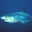

In [12]:
train_image[49999]

In [13]:
train_image[49999].shape

(32, 32, 3)

In [14]:
type(train_image[49999])

numpy.ndarray

array([[[141, 134, 115],
        [167, 160, 142],
        [161, 154, 137],
        ...,
        [ 59,  49,  38],
        [ 44,  34,  23],
        [ 80,  70,  60]],

       [[107,  99,  85],
        [146, 139, 121],
        [153, 147, 124],
        ...,
        [ 40,  30,  18],
        [103,  94,  81],
        [165, 155, 143]],

       [[ 71,  64,  49],
        [112, 105,  87],
        [120, 114,  91],
        ...,
        [ 96,  87,  72],
        [154, 145, 130],
        [180, 170, 155]],

       ...,

       [[119, 112,  94],
        [ 92,  86,  68],
        [ 79,  72,  54],
        ...,
        [147, 138, 121],
        [ 95,  86,  69],
        [ 59,  50,  33]],

       [[130, 122, 104],
        [114, 107,  89],
        [ 84,  77,  59],
        ...,
        [ 71,  62,  45],
        [ 52,  43,  26],
        [ 81,  72,  55]],

       [[141, 133, 115],
        [122, 115,  98],
        [106,  99,  81],
        ...,
        [ 66,  57,  40],
        [ 98,  89,  72],
        [140, 131, 114]]], shape=(32, 32, 3), dtype=uint8)
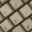

In [15]:
train_image[4999]

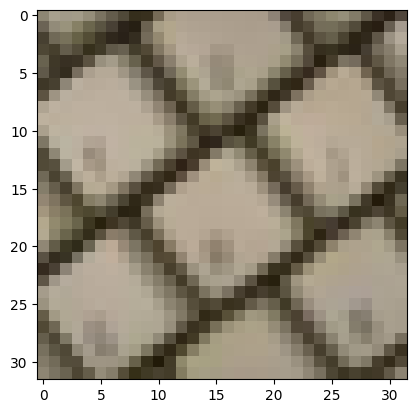

In [16]:
plt.imshow(train_image[4999])

In [17]:
train_image.shape

(50000, 32, 32, 3)

In [18]:
train_image.shape[0]

50000

## Splitting Training and Validation Data

In [19]:
generator = torch.Generator().manual_seed(42)
indices= torch.randperm(train_image.shape[0], generator= generator)
indices

tensor([37542, 44491,   216,  ..., 40730, 25847, 33082])

In [20]:
train_indices = indices[:45000].tolist()
validaion_indices = indices[45000:].tolist()
type(train_indices)

list

## Creating Training and Validation Subsets

In [21]:
train_data = Subset(traindata, train_indices)
val_data = Subset(validationdata, validaion_indices)

## Creating DataLoaders

In [22]:
TrainLoader = DataLoader(train_data, batch_size= 128, shuffle= True)
TestLoader = DataLoader(testdata, batch_size= 128, shuffle= False)
ValidationLoader = DataLoader(val_data, batch_size= 128, shuffle= False)

## Defining device

In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## Designing our 2D CNN Model

In [24]:
class CNN2D(nn.Module):
  def __init__(self, in_channels, num_classes):
    super(CNN2D, self).__init__()

    self.Blocks = nn.Sequential(nn.Conv2d(in_channels= in_channels, out_channels= 64, kernel_size= 3, padding= 1, stride= 1),
                              nn.BatchNorm2d(num_features= 64),
                              nn.ReLU(inplace= False),
                              nn.MaxPool2d(kernel_size= 2, stride= 2),

                              nn.Conv2d(in_channels= 64, out_channels= 128, kernel_size= 3, padding= 1, stride= 1),
                              nn.BatchNorm2d(num_features= 128),
                              nn.ReLU(inplace= False),
                              nn.MaxPool2d(kernel_size= 2, stride= 2),

                              nn.Conv2d(in_channels= 128, out_channels= 256, kernel_size= 3, padding= 1, stride= 1),
                              nn.BatchNorm2d(num_features= 256),
                              nn.ReLU(inplace= False),
                              nn.MaxPool2d(kernel_size= 2, stride= 2))

    self.FC = nn.Sequential(nn.Flatten(),
                            nn.Linear(256*4*4, 128),
                            nn.ReLU(),
                            nn.Dropout(p= 0.2),
                            nn.Linear(128, num_classes))
  def forward(self, x):
    x = self.Blocks(x)
    x = self.FC(x)

    return x

In [25]:
torch.manual_seed(42)

CNN_Model = CNN2D(3, 100).to(device)
CNN_Model

CNN2D(
  (Blocks): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (FC): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, in

In [26]:
total_para = sum(p.numel() for p in CNN_Model.parameters())
total_para

909028

In [27]:
CNN_Model.state_dict()

OrderedDict([('Blocks.0.weight',
              tensor([[[[ 0.1471,  0.1597, -0.0451],
                        [ 0.1768, -0.0422,  0.0388],
                        [-0.0937,  0.1130,  0.1697]],
              
                       [[-0.1412,  0.1673,  0.0360],
                        [ 0.1422,  0.0261,  0.0928],
                        [-0.0272,  0.1484,  0.0284]],
              
                       [[-0.0898,  0.0491, -0.0887],
                        [-0.0226, -0.0782,  0.1277],
                        [-0.1519, -0.0887, -0.0543]]],
              
              
                      [[[-0.1157,  0.0182, -0.1901],
                        [ 0.1738, -0.1635,  0.1486],
                        [ 0.0320, -0.0625,  0.1189]],
              
                       [[ 0.0300,  0.1555,  0.0210],
                        [-0.0607,  0.0517, -0.0522],
                        [ 0.0810,  0.1718,  0.1112]],
              
                       [[-0.0841,  0.1111,  0.0344],
                       

## Setup loss and optimizer

In [28]:
loss = nn.CrossEntropyLoss()
optimizer = optim.SGD(CNN_Model.parameters(), lr= 0.001, momentum= 0.9)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100)

## Training the Model for One Epoch

In [29]:
def train_per_one_epoch(model, dataloader, Loss, Optimizer):

  torch.manual_seed(42)

  model.train()
  train_loss, train_total, train_correct = 0, 0, 0

  for x, y in dataloader:

    x, y = x.to(device), y.to(device)
    tr_out = model(x)
    trainloss = Loss(tr_out, y)

    _, tr_pre = torch.max(tr_out, dim= 1)


    Optimizer.zero_grad()
    trainloss.backward()
    Optimizer.step()

    train_loss += trainloss.item()
    train_total += tr_out.size(0)
    train_correct += (tr_pre == y).sum().item()


  train_accuracy = 100*(train_correct/train_total)

  return train_loss, train_accuracy

## Validation the Model for One Epoch

In [30]:
def validation_per_one_epoch(model, dataloader, Loss):

  model.eval()

  val_loss, val_correct, val_total = 0, 0, 0
  with torch.inference_mode():

    for x, y in dataloader:
      x, y = x.to(device), y.to(device)

      val_out = model(x)
      valloss = Loss(val_out, y)
      _, val_pre = torch.max(val_out, dim= 1)

      val_loss += valloss.item()

      val_total += val_out.size(0)

      val_correct += (val_pre == y).sum().item()

  val_accuracy = 100 * (val_correct/val_total)

  return val_loss, val_accuracy

In [31]:
%%script false --no-raise-error

init_time = time.time()

tr_loss, tr_acc = train_per_one_epoch(CNN_Model, TrainLoader, loss, optimizer)

final_time = time.time()

execution_time = final_time - init_time

print(f'Execution Time: {execution_time:.4f} seconds')

## Training and Validation Loop

In [32]:
best_val_acc = 0
best_epoch = 0
patience = 7
counter = 0
min_delta = 0.1

In [33]:
start = time.time()


epochs = 40

epoch_list = []
tr_loss_list = []
tr_acc_list = []
val_loss_list = []
val_acc_list = []


for epoch in range(epochs):

  tr_loss, tr_acc = train_per_one_epoch(CNN_Model, TrainLoader, loss, optimizer)
  val_loss, val_acc = validation_per_one_epoch(CNN_Model, ValidationLoader, loss)

  scheduler.step()
  print(f'Learning Rate: {optimizer.param_groups[0]['lr']}')



  if val_acc > best_val_acc + min_delta:
    best_val_acc = val_acc
    best_epoch = epoch + 1
    counter = 0

    best_state = copy.deepcopy(CNN_Model.state_dict())
    best_info = {'epoch': best_epoch,
                 'train_loss': tr_loss, 'train_acc': tr_acc,
                 'val_loss': val_loss, 'val_acc': val_acc}

  else:
    counter += 1

    if counter >= patience:
      print(f'\nEarly stopping at epoch {epoch+1}. Best epoch: {best_epoch} '
                  f'(Val Acc: {best_val_acc:.2f}%)')
      break



  epoch_list.append((epoch + 1))
  tr_loss_list.append(tr_loss)
  tr_acc_list.append(tr_acc)
  val_loss_list.append(val_loss)
  val_acc_list.append(val_acc)

  print(f'Epochs: {epoch+1}| Train Loss: {tr_loss}| Validation Loss: {val_loss}')
  print(f'Train Accuracy: {tr_acc: .2f}%| Validation Accuracy: {val_acc: .2f}%')
  print(f'-'*60)


end = time.time()

execution_time = end - start

print(f'Execution time: {execution_time: .4f} Seconds')

Learning Rate: 0.0009997532801828658
Epochs: 1| Train Loss: 1538.4496898651123| Validation Loss: 160.4680769443512
Train Accuracy:  5.04%| Validation Accuracy:  10.86%
------------------------------------------------------------
Learning Rate: 0.0009990133642141358
Epochs: 2| Train Loss: 1378.7949573993683| Validation Loss: 144.85280179977417
Train Accuracy:  10.66%| Validation Accuracy:  16.72%
------------------------------------------------------------
Learning Rate: 0.00099778098230154
Epochs: 3| Train Loss: 1275.200118303299| Validation Loss: 134.20979642868042
Train Accuracy:  14.98%| Validation Accuracy:  21.76%
------------------------------------------------------------
Learning Rate: 0.000996057350657239
Epochs: 4| Train Loss: 1192.7264404296875| Validation Loss: 124.93325996398926
Train Accuracy:  18.94%| Validation Accuracy:  25.88%
------------------------------------------------------------
Learning Rate: 0.0009938441702975688
Epochs: 5| Train Loss: 1122.6237256526947| Va

In [34]:
torch.save({'model_state_dict': best_state, **best_info}, 'best_model.pth')
print(f'Best model:\nEpoch: {best_epoch}\nValidation Accuracy: {best_val_acc:.2f}%')

CNN_Model.load_state_dict(best_state)

Best model:
Epoch: 20
Validation Accuracy: 40.90%


<All keys matched successfully>

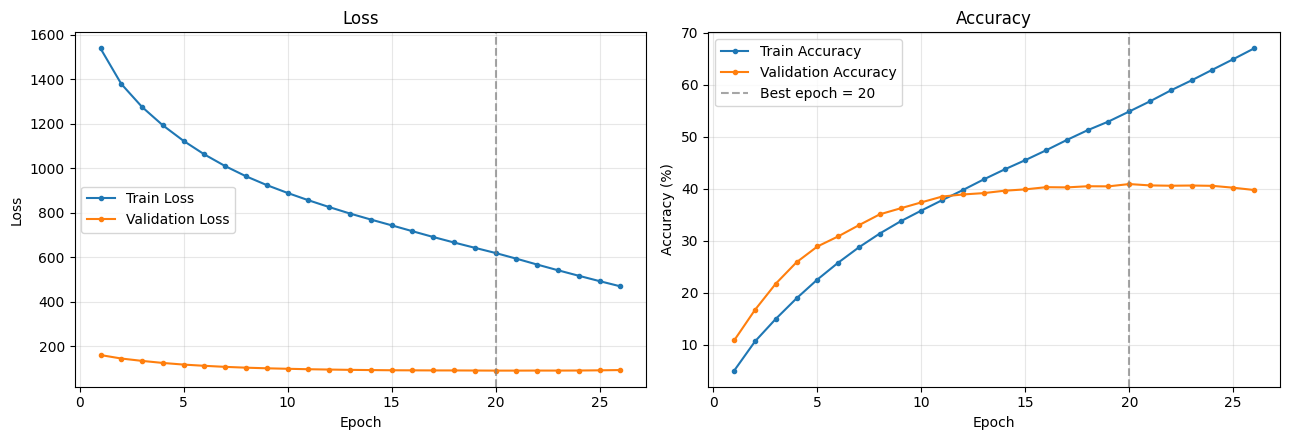

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(epoch_list, tr_loss_list, label='Train Loss', marker='o', markersize=3)
ax[0].plot(epoch_list, val_loss_list, label='Validation Loss', marker='o', markersize=3)
ax[0].set_title('Loss')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].grid(alpha=0.3)
ax[0].legend()

ax[1].plot(epoch_list, tr_acc_list, label='Train Accuracy', marker='o', markersize=3)
ax[1].plot(epoch_list, val_acc_list, label='Validation Accuracy', marker='o', markersize=3)
ax[1].set_title('Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy (%)')
ax[1].grid(alpha=0.3)
ax[1].legend()

if best_epoch > 0:
    ax[0].axvline(best_epoch, color='gray', linestyle='--', alpha=0.7)
    ax[1].axvline(best_epoch, color='gray', linestyle='--', alpha=0.7, label=f'Best epoch = {best_epoch}')
    ax[1].legend()

plt.tight_layout()
plt.show()